# Classification MNIST : données, CNN et référence supervisée

**Projet de Deep Learning — M2 MLSD**

**Équipe 4 étudiantes:** 
Sabrina BELARIBI <br> 
Chaimaa ARSALANE <br> 
Sirine BOUGHANEM <br>
Manel LAKROUZ

**Article de référence :** Gidaris, Singh et Komodakis, *Unsupervised Representation Learning by Predicting Image Rotations* (2018).

Ce notebook présente les données, le CNN commun et la référence supervisée du projet. L'objectif du groupe est d'étudier si le préentraînement RotNet améliore la classification avec 100 labels.

La référence présentée ici utilise les **40 000 labels** du pool. Elle fournit un repère et ne respecte pas la contrainte des 100 labels. Les fonctions réutilisables sont définies dans **src/**.

## 1. Préparation de l’environnement

Nous importons ici les bibliothèques et les fonctions communes utilisées dans le notebook.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader, Subset

from src.data import load_mnist
from src.models import SmallCNN
from src.engine import evaluate, set_seed, train_one_epoch
from src.train_supervised import train_reference

## 2. Chargement et exploration des données

### 2.1 Chargement et nombre d'images

Nous commençons par charger les données et afficher le nombre d'images dans l'ensemble d'entraînement officiel, dans le pool sélectionné pour le projet et dans l'ensemble de test.

In [2]:
pool_train, test = load_mnist()

print(f"Ensemble d’apprentissage officiel : {len(pool_train.dataset)} images")
print(f"Pool d’apprentissage sélectionné : {len(pool_train)} images")
print(f"Ensemble de test officiel : {len(test)} images")

Ensemble d’apprentissage officiel : 60000 images
Pool d’apprentissage sélectionné : 40000 images
Ensemble de test officiel : 10000 images


**Interprétation:** Le jeu d'entraînement MNIST chargé contient **60 000 images**. Pour respecter les 40 000 images indiquées dans la consigne, notre fonction en sélectionne 40 000 parmi ces 60 000. Le jeu de test officiel contient **10 000 images** et reste séparé de l'entraînement.

Le choix des 40 000 images utilise la graine 42 et se fait sans remise, une image ne peut donc pas être tirée deux fois.

### 2.2 Vérification d'une image

Observons les dimensions, le chiffre associé et les valeurs des pixels de la première image du pool.

In [3]:
image, label = pool_train[0]
print(f"Dimensions : {tuple(image.shape)}")
print(f"Chiffre associé : {label}")
print(f"Valeurs des pixels : de {image.min().item():.2f} à {image.max().item():.2f}")

Dimensions : (1, 28, 28)
Chiffre associé : 6
Valeurs des pixels : de 0.00 à 1.00


**Interprétation:** La forme **(1, 28, 28)** correspond à un canal en niveaux de gris et à une image de 28 × 28 pixels. Le label affiché est le chiffre attendu pour cet exemple (=6). La fonction de chargement applique **ToTensor()**, elle convertit les images en tenseurs de pixels compris entre 0 et 1.

### 2.3 Visualisation de quelques exemples

Affichons dix images du pool et le chiffre associé à chacune.

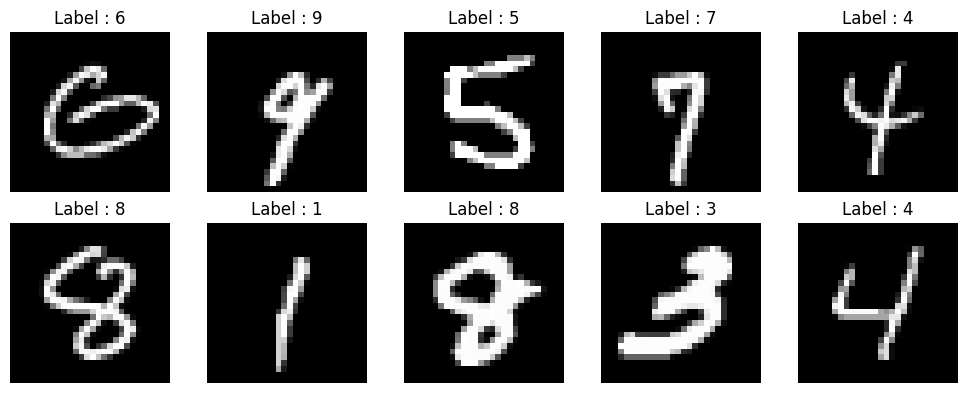

In [4]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for i, ax in enumerate(axes.flat):
    image, label = pool_train[i]
    ax.imshow(image.squeeze(0), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label : {label}")
    ax.axis("off")
plt.tight_layout()
plt.show()

**Lecture:** Ces exemples montrent la variabilité des écritures manuscrites. Une inspection qualitative ne permet pas à elle seule de mesurer la performance du modèle.

### Répartition des chiffres dans le pool

Comptons les images de chaque chiffre parmi les 40 000 images sélectionnées.

Chiffre 0 : 3962 images
Chiffre 1 : 4488 images
Chiffre 2 : 4013 images
Chiffre 3 : 4116 images
Chiffre 4 : 3854 images
Chiffre 5 : 3616 images
Chiffre 6 : 3892 images
Chiffre 7 : 4168 images
Chiffre 8 : 3903 images
Chiffre 9 : 3988 images
Total : 40000 images


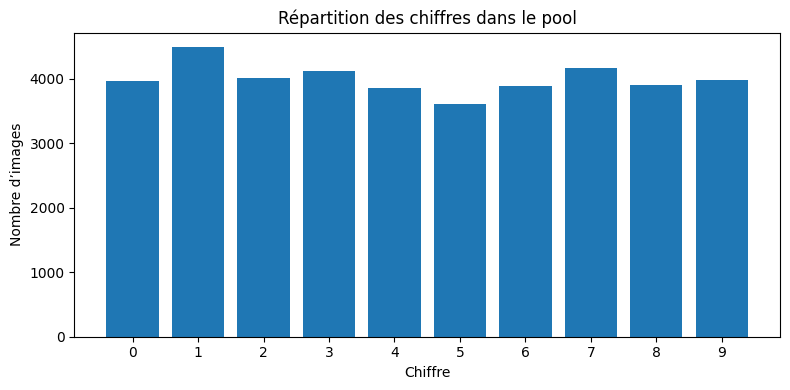

In [5]:
# pool_train.indices désigne les positions dans le train officiel.
indices_pool = torch.as_tensor(pool_train.indices, dtype=torch.long)
labels_pool = pool_train.dataset.targets[indices_pool]
effectifs = torch.bincount(labels_pool, minlength=10)
for chiffre, effectif in enumerate(effectifs.tolist()):
    print(f"Chiffre {chiffre} : {effectif} images")
print(f"Total : {effectifs.sum().item()} images")

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(range(10), effectifs.tolist())
ax.set(xlabel="Chiffre", ylabel="Nombre d’images", title="Répartition des chiffres dans le pool")
ax.set_xticks(range(10))
fig.tight_layout()
plt.show()

**Interprétation :** Les dix chiffres sont bien représentés dans notre pool, avec environ 4 000 images par chiffre. La répartition n’est pas exactement équilibrée, le chiffre 1 apparaît le plus souvent, tandis que le 5 est le moins présent. Nous n’avons pas imposé le même nombre d’images pour chaque chiffre lors du tirage.

## 3. Construction du CNN commun

Nous créons un modèle pour la reconnaissance des chiffres et un autre pour la prédiction des rotations. Ils utilisent tous deux la classe **SmallCNN** définie dans **src/models.py**. Affichons d'abord l'architecture du modèle à 10 sorties.

In [6]:
modele_chiffres = SmallCNN(num_classes=10)
modele_rotations = SmallCNN(num_classes=4)
print(modele_chiffres)

SmallCNN(
  (features): Sequential(
    (0): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=1568, out_features=64, bias=True)
    (8): ReLU()
  )
  (classifier): Linear(in_features=64, out_features=10, bias=True)
)


In [7]:
lot = torch.stack([pool_train[i][0] for i in range(8)])
with torch.no_grad():
    caracteristiques = modele_chiffres.features(lot)
    scores_chiffres = modele_chiffres(lot)
    scores_rotations = modele_rotations(lot)

print("Lot d'images :", tuple(lot.shape))
print("Caractéristiques :", tuple(caracteristiques.shape))
print("Scores des chiffres :", tuple(scores_chiffres.shape))
print("Scores des rotations :", tuple(scores_rotations.shape))
assert caracteristiques.shape == (8, 64)
assert scores_chiffres.shape == (8, 10)
assert scores_rotations.shape == (8, 4)

Lot d'images : (8, 1, 28, 28)
Caractéristiques : (8, 64)
Scores des chiffres : (8, 10)
Scores des rotations : (8, 4)


**Interprétation:** Nous avons testé le CNN avec 8 images. Il produit bien 10 scores par image pour la classification des chiffres et 4 scores par image pour la prédiction des rotations. Les dimensions obtenues sont donc celles attendues.

## 4. Fonctions communes d'entraînement et d'évaluation

Avant l'expérience complète, nous essayons les fonctions communes sur 8 images avec un modèle neuf. Cet essai vérifie que les calculs s'exécutent, l'évaluation porte sur les mêmes images que l'entraînement et ne mesure donc pas la généralisation.

In [8]:
set_seed(42)
appareil = torch.device("cpu")
mini_lot = DataLoader(Subset(pool_train, range(8)), batch_size=4)
modele_essai = SmallCNN(num_classes=10).to(appareil)
optimiseur = torch.optim.Adam(modele_essai.parameters(), lr=0.001)

entrainement = train_one_epoch(modele_essai, mini_lot, optimiseur, appareil)
evaluation = evaluate(modele_essai, mini_lot, appareil)
print("Entraînement :", entrainement)
print("Évaluation sur les mêmes 8 images :", evaluation["accuracy"])
print("Taille de la matrice de confusion :", evaluation["confusion_matrix"].shape)

Entraînement : {'loss': 2.316800355911255, 'accuracy': 0.0}
Évaluation sur les mêmes 8 images : 0.5
Taille de la matrice de confusion : torch.Size([10, 10])


**Interprétation:** Ce petit essai montre que les fonctions d’entraînement et d’évaluation fonctionnent. Le modèle reconnaît 4 images sur 8 après l’entraînement, mais ce résultat ne permet pas de juger sa performance, il a été évalué sur les mêmes images que celles utilisées pour apprendre.

## 5. Référence supervisée A — 40 000 labels

Nous avons entraîné un `SmallCNN` avec les 40 000 labels, Adam (taux 0,001), des lots de 128 images, 30 époques et la graine 42. Le modèle final a été évalué sur les 10 000 images de test.

Par défaut, la cellule suivante charge les résultats déjà obtenus : elle ne relance pas l’entraînement. Pour faire un nouvel essai, remplacer `False` par `True` et choisir dans `DOSSIER_RESULTATS` un dossier qui n’existe pas encore. Les courbes et la matrice utiliseront alors les résultats de ce même dossier. Les résultats existants ne sont jamais écrasés.

In [9]:
# Par défaut, on relit les résultats existants sans entraîner le modèle.
DOSSIER_RESULTATS = Path("results/reference_supervisee_40000_labels")
RELANCER_ENTRAINEMENT = False
GRAINE = 42

if RELANCER_ENTRAINEMENT:
    # Choisir ci-dessus un dossier qui n'existe pas encore.
    modele_reference, resultats_reference = train_reference(
        pool_train, test, output_dir=DOSSIER_RESULTATS,
        seed=GRAINE, epochs=30, batch_size=128, learning_rate=0.001,
    )
else:
    with (DOSSIER_RESULTATS / "metrics.json").open(encoding="utf-8") as fichier:
        resultats_reference = json.load(fichier)

print(f"Dossier des résultats : {DOSSIER_RESULTATS}")
print(f"Graine enregistrée : {resultats_reference['config']['seed']}")
print(f"Précision de test : {resultats_reference['test_accuracy']:.2%}")

Dossier des résultats : results\reference_supervisee_40000_labels
Graine enregistrée : 42
Précision de test : 99.04%


## 6. Évaluation de la référence supervisée — 40 000 labels

L'exécution enregistrée donne **9 904 bonnes réponses sur 10 000**, soit **99,04 %** et 96 erreurs. Ce résultat correspond à une seule exécution, graine 42 : il ne permet pas d'estimer la variabilité entre initialisations. Il s'agit d'une référence à 40 000 labels, pas d'un résultat à 100 labels.

Le test étant réservé à l'évaluation finale, son score ne doit pas servir à choisir les hyperparamètres ou la meilleure époque.

Ces chiffres décrivent l’exécution enregistrée avec la graine 42 ; si un nouvel essai est sélectionné, il faudra actualiser leur interprétation.

## 7. Courbes et analyse de l'apprentissage

À partir des métriques enregistrées, traçons la perte et la précision à chaque époque sur les images d'entraînement. Ces courbes peuvent être affichées sans relancer l'entraînement.

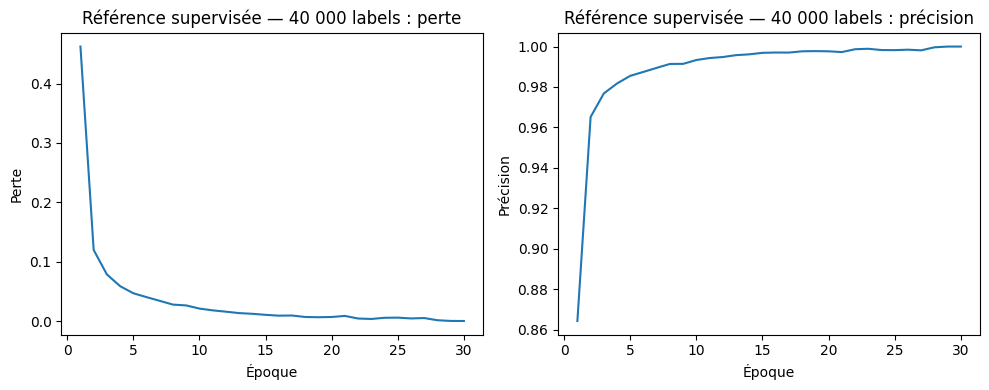

In [10]:
historique = resultats_reference["training_history"]
epoques = [ligne["epoch"] for ligne in historique]
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(epoques, [ligne["loss"] for ligne in historique])
axes[0].set(title="Référence supervisée — 40 000 labels : perte", xlabel="Époque", ylabel="Perte")
axes[1].plot(epoques, [ligne["accuracy"] for ligne in historique])
axes[1].set(title="Référence supervisée — 40 000 labels : précision", xlabel="Époque", ylabel="Précision")
plt.tight_layout()
plt.show()

**Interprétation:** Au fil des époques, la perte diminue et la précision augmente. Le modèle apprend donc à reconnaître les images d’entraînement. Il atteint également 99,04 % de précision sur le jeu de test, même s’il commet encore quelques erreurs sur des images qu’il n’a pas vues pendant l’apprentissage.

Cette interprétation décrit les résultats enregistrés avec la graine 42.

## 8. Analyse des erreurs : matrice de confusion

La matrice est relue depuis les résultats sauvegardés après l'évaluation finale, sans réentraîner le modèle. Chaque ligne correspond au vrai chiffre et chaque colonne au chiffre prédit. La diagonale représente les bonnes réponses, les autres cases représentent les erreurs.

Nombre d’images évaluées : 10000
Prédictions correctes : 9904
Erreurs : 96


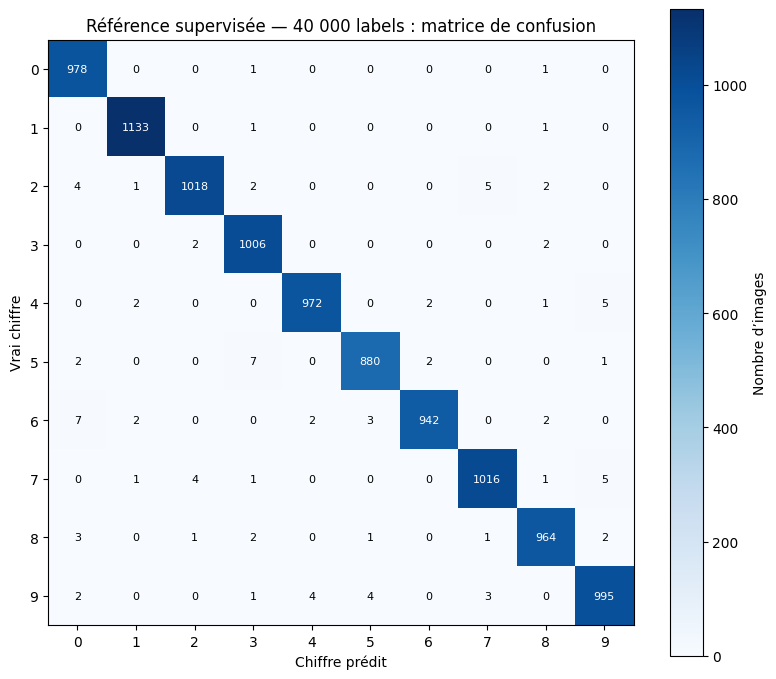

In [11]:
matrice = np.asarray(resultats_reference["confusion_matrix"])
print(f"Nombre d’images évaluées : {matrice.sum()}")
print(f"Prédictions correctes : {np.trace(matrice)}")
print(f"Erreurs : {matrice.sum() - np.trace(matrice)}")

fig, ax = plt.subplots(figsize=(8, 7))
image = ax.imshow(matrice, cmap="Blues")
fig.colorbar(image, ax=ax, label="Nombre d’images")
ax.set(xticks=range(10), yticks=range(10), xlabel="Chiffre prédit",
       ylabel="Vrai chiffre", title="Référence supervisée — 40 000 labels : matrice de confusion")
for ligne in range(10):
    for colonne in range(10):
        valeur = matrice[ligne, colonne]
        ax.text(colonne, ligne, str(valeur), ha="center", va="center",
                color="white" if valeur > matrice.max() / 2 else "black", fontsize=8)
fig.tight_layout()
plt.show()

**Interprétation:** La plupart des valeurs se trouvent sur la diagonale : le modèle reconnaît donc correctement la grande majorité des chiffres. Il reste quelques confusions, par exemple 7 images de 5 sont prédites comme des 3. Cela est cohérent avec la précision de 99,04 % obtenue sur le jeu de test.

Cet exemple concerne les résultats enregistrés avec la graine 42.